# Galaxien sailkapena konboluzio-sareak erabiliz

Proiektu honen helburua galaxia baten irudi batetik galaxia horren mota sailkatzea gai den konboluzio-sare (CNN) bat diseinatzea da.

Hasi aurretik, proiektuan zehar erabiliko ditugun Python paketeak instalatuta daudela bermatuko dugu.

In [ ]:
%%bash

packages=(
    'gdown'
    'numpy'
    'imageio'
    'matplotlib'
    'pandas'
    'torch'
    'scikit-learn'
    'torchvision'
    'torchsummary'
)

getPackageVersion() {
    local package_name=$1
    pip show "$package_name" 2>/dev/null \
        | grep Version: \
        | sed -E 's/^Version: (.*)/v\1/'
}

for package in "${packages[@]}"; do
    version=$(getPackageVersion "$package")
    if [ -n "$version" ]; then
        echo "$package ($version) jada instalatuta dago."
    else
        echo "Instalatzen $package..."
        pip install "$package" > /dev/null 2>&1
        if [ $? -eq 0 ]; then
            version=$(getPackageVersion "$package")
            echo "$package ($version) ondo instalatu da."
        else
            echo "Ezin izan da $package instalatu."
        fi
    fi
done

gdown (v5.2.2) jada instalatuta dago.
numpy (v2.0.2) jada instalatuta dago.
imageio (v2.37.3) jada instalatuta dago.
matplotlib (v3.10.0) jada instalatuta dago.
pandas (v2.2.2) jada instalatuta dago.
torch (v2.10.0+cu128) jada instalatuta dago.
scikit-learn (v1.6.1) jada instalatuta dago.
torchvision (v0.25.0+cu128) jada instalatuta dago.
torchsummary (v1.5.1) jada instalatuta dago.


Jarraian, GPUren bat erabilgarri dagoen begiratuko dugu, eta gorde egingo dugu erabilgarri egonez gero, beranduago CNNa GPUan exekutatu ahal izateko CPUan ordez.

In [ ]:
import torch

try:
    import torch_directml
    device = torch_directml.device()
    print('DirectML gailua erabiltzen.')
except ImportError:
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(f'{device} gailua erabiltzen.')

cuda gailua erabiltzen.


# 1.&nbsp;Galaxia datuak

## 1.1 Datuak deskargatu

Proiektu honetan erabilitako datuak [https://www.kaggle.com/c/galaxy-zoo-the-galaxy-challenge](https://www.kaggle.com/c/galaxy-zoo-the-galaxy-challenge)-tik eskuratu dira. Hala ere, web-orrialde honetatik datuak deskargatu ahal izateko izena eman behar da eta zailtasuna ematen du datuak automatikoki deskargatzeko. Honi aurre egiteko, datuak deskargatu egin dira eta eskuragarri jarri dira Google Drive-en.

In [ ]:
import os
from gdown import download
from zipfile import ZipFile

data_folder = './data'
os.makedirs(data_folder, exist_ok=True)

# Deskargatu images_training_rev1.zip

images_file_id = '1irixY08voLmY2jvmhs4pa8ZpbwNTaqRd'
images_output_filename = 'images_training_rev1.zip'

image_folder = os.path.join(data_folder, os.path.splitext(images_output_filename)[0])
images_present = os.path.exists(image_folder) and any(f.endswith('.jpg') for f in os.listdir(image_folder))
images_download_path = os.path.join(data_folder, images_output_filename)
images_downloaded = os.path.exists(images_download_path)

if not images_present:
    if not images_downloaded:
        try:
            download(id=images_file_id, output=images_download_path, fuzzy=True)
            print(f"'{images_output_filename}' fitxategia deskargatu da '{data_folder}' bidera.")
        except Exception as e:
            print(f"Errorea gertatu da {images_output_filename} deskargatzean: {e}")

    with ZipFile(images_download_path, 'r') as f:
        f.extractall(data_folder)
        print(f"Irudiak erauzi dira {data_folder} bidera.")

# Deskargatu training_solutions_rev1.zip

solutions_file_id = '1JxwbX76rJJNe7MrSvQh0W_KFNEE5WgnP'
solutions_output_filename = 'training_solutions_rev1.zip'

solutions_filename = os.path.splitext(solutions_output_filename)[0] + '.csv'
solutions_file_path = os.path.join(data_folder, solutions_filename)
solutions_present = os.path.exists(solutions_file_path)
solutions_download_path = os.path.join(data_folder, solutions_output_filename)
solutions_downloaded = os.path.exists(solutions_download_path)

if not solutions_present:
    if not solutions_downloaded:
        try:
            download(id=solutions_file_id, output=solutions_download_path, fuzzy=True)
            print(f"'{solutions_output_filename}' fitxategia deskargatu da '{data_folder}' bidera.")
        except Exception as e:
            print(f"Errorea gertatu da {solutions_output_filename} deskargatzean: {e}.")

    with ZipFile(solutions_download_path, 'r') as f:
        f.extractall(data_folder)
        print(f"Soluzioak erauzi dira {data_folder} bidera.")

Downloading...
From (original): https://drive.google.com/uc?id=1irixY08voLmY2jvmhs4pa8ZpbwNTaqRd
From (redirected): https://drive.google.com/uc?id=1irixY08voLmY2jvmhs4pa8ZpbwNTaqRd&confirm=t&uuid=b43bc473-7c93-46d0-86dd-4936dfac7477
To: /content/data/images_training_rev1.zip
100%|██████████| 830M/830M [00:16<00:00, 49.7MB/s]


'images_training_rev1.zip' fitxategia deskargatu da './data' bidera.
Irudiak erauzi dira ./data bidera.


Downloading...
From: https://drive.google.com/uc?id=1JxwbX76rJJNe7MrSvQh0W_KFNEE5WgnP
To: /content/data/training_solutions_rev1.zip
100%|██████████| 4.85M/4.85M [00:00<00:00, 17.8MB/s]

'training_solutions_rev1.zip' fitxategia deskargatu da './data' bidera.
Soluzioak erauzi dira ./data bidera.



Galaxia batzuk ausaz hautatuko ditugu ikusteko ea ondo deskargatu diren.

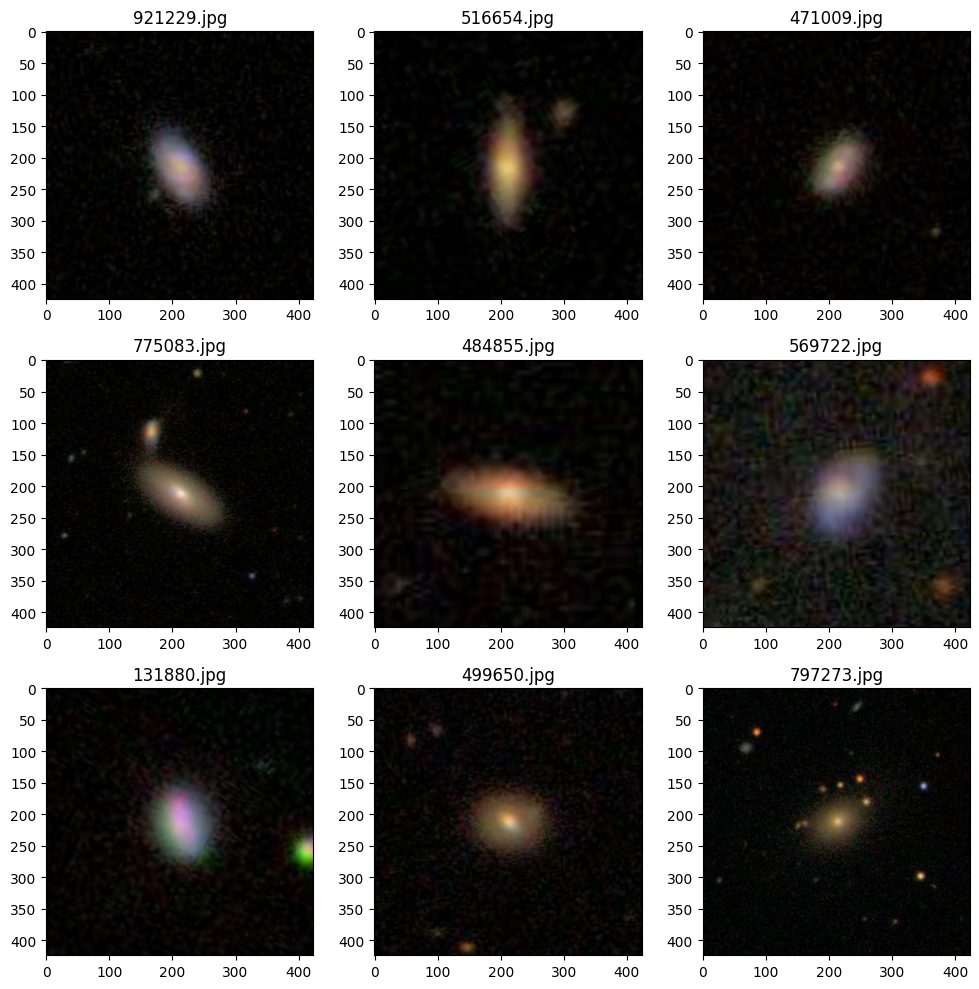

In [ ]:
import random
from imageio.v2 import imread
import matplotlib.pyplot as plt

# Galaxia guztien fitxategi-izenak eskuratu
all_image_files = [f for f in os.listdir(image_folder) if f.endswith('.jpg')]

# 9 hautatu ausaz
sampled_images = random.sample(all_image_files, 9)

plt.figure(figsize=(10, 10))
for i, image_name in enumerate(sampled_images):
    image_path = os.path.join(image_folder, image_name)
    img = imread(image_path)
    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(image_name)
plt.tight_layout()
plt.show()

## 1.2 Datuak ikuskatu

Pertsonek erabaki-zuhaitz habiaratu bati erantzuten diote irudiak sailkatzeko. Erantzun hauek bildu egiten dira eta erantzun bakoitzaren probabilitatea kalkulatu eta ezaugarri gisa adierazten da.

Galdera baten ezaugarri-multzoaren hasierako probabilitateen baturak 1 emango du. Aurreko galdera batetik sortutako galdera baten ezaugarri-multzoaren probabilitateen baturak ere 1 emango du, aurreko erantzunaren ezaugarriaren probabilitatearekin pisatu aurretik.

Gure datu-multzoak 61578 irudi ditu eta irudi bakoitzak galaxia bat adierazten du. Horrez gain, irudiak 424x424 bereizmen karratu dute eta koloretan daude.

In [ ]:
image_count = sum(1 for entry in os.scandir(image_folder) if entry.is_file() and entry.name.endswith('.jpg'))
print(f'Irudi kopurua: {image_count}')

image_height = 424
image_width = 424

resolution_counts = {}
for filename in os.listdir(image_folder):
    if filename.endswith('.jpg'):
        image_path = os.path.join(image_folder, filename)
        img = imread(image_path)
        image_height = img.shape[0]
        image_width = img.shape[1]
        resolution_string = f'{img.shape[0]}x{img.shape[1]}x{img.shape[2]}'
        if resolution_string not in resolution_counts:
            resolution_counts[resolution_string] = 0
        resolution_counts[resolution_string] += 1

print("Bereizmenen kontaketa:")
for resolution, count in resolution_counts.items():
    print(f"    {resolution}: {count}")

Irudi kopurua: 61578
Bereizmenen kontaketa:
    424x424x3: 61578


Jarraian, erabaki-zuhaitza eta galdera bakoitzaren erantzunak, ezaugarri identifikatzailea eta zuhaitzeko hurrengo galdera zerrendatzen dira.

- **Q1.** Objektua galaxia leun bat, ezaugarridun/diskodun galaxia bat edo izar bat da?
    - Leuna *(Class1.1)* *[Q7]*
    - Ezaugarriduna edo diskoduna *(Class1.2)* *[Q2]*
    - Izarra edo artefaktua *(Class1.3)* *[end]*
- **Q2.** Galaxiaren ertza ikusten da?
    - Bai *(Class2.1)* *[Q9]*
    - Ez *(Class2.2)* *[Q3]*
- **Q3.** Barrarik ba al dago?
    - Bai *(Class3.1)* *[Q4]*
    - Ez *(Class3.2)* *[Q4]*
- **Q4.** Eredu espiralik ba al dago?
    - Bai *(Class4.1)* *[Q10]*
    - Ez *(Class4.2)* *[Q5]*
- **Q5.** Nolako nabarmena da erdiko tontorra?
    - Tontorrik ez *(Class5.1)* *[Q6]*
    - Antzeman daiteke *(Class5.2)* *[Q6]*
    - Begi bistakoa *(Class5.3)* *[Q6]*
    - Nagusia *(Class5.4)* *[Q6]*
- **Q6.** Galaxiak ezaugarri "arrarorik" ba al du?
    - Bai *(Class6.1)* *[Q8]*
    - Ez *(Class6.2)* *[end]*
- **Q7.** Nolako biribila da galaxia leuna?
    - Guztiz biribila *(Class7.1)* *[Q6]*
    - Tartekoa *(Class7.2)* *[Q6]*
    - Zigarro-itxurakoa *(Class7.3)* *[Q6]*
- **Q8.** Zein da ezaugarri arraroa?
    - Eraztuna *(Class8.1)* *[end]*
    - Lentea edo arkua *(Class8.2)* *[end]*
    - Nahasia *(Class8.3)* *[end]*
    - Irregularra *(Class8.4)* *[end]*
    - Bestelakoa *(Class8.5)* *[end]*
    - Bat-egitea *(Class8.6)* *[end]*
    - Hauts-bidea *(Class8.7)* *[end]*
- **Q9.** Zein itxura du tontorrak ertza ikusi daitekeen galaxian?
    - Biribila *(Class9.1)* *[Q6]*
    - Kutxa-itxurakoa *(Class9.2)* *[Q6]*
    - Tontorrik ez *(Class9.3)* *[Q6]*
- **Q10.** Nolako gertu daude beso espiralak?
    - Gertu *(Class10.1)* *[Q11]*
    - Tartekoa *(Class10.2)* *[Q11]*
    - Solte *(Class10.3)* *[Q11]*
- **Q11.** Zenbat beso espiral daude?
    - 1 *(Class11.1)* *[Q5]*
    - 2 *(Class11.2)* *[Q5]*
    - 3 *(Class11.3)* *[Q5]*
    - 4 *(Class11.4)* *[Q5]*
    - Lau baino gehiago *(Class11.5)* *[Q5]*
    - Ez dakit *(Class11.6)* *[Q5]*

Hurrengo irudiak erabaki-zuhaitza irudikatzen du: 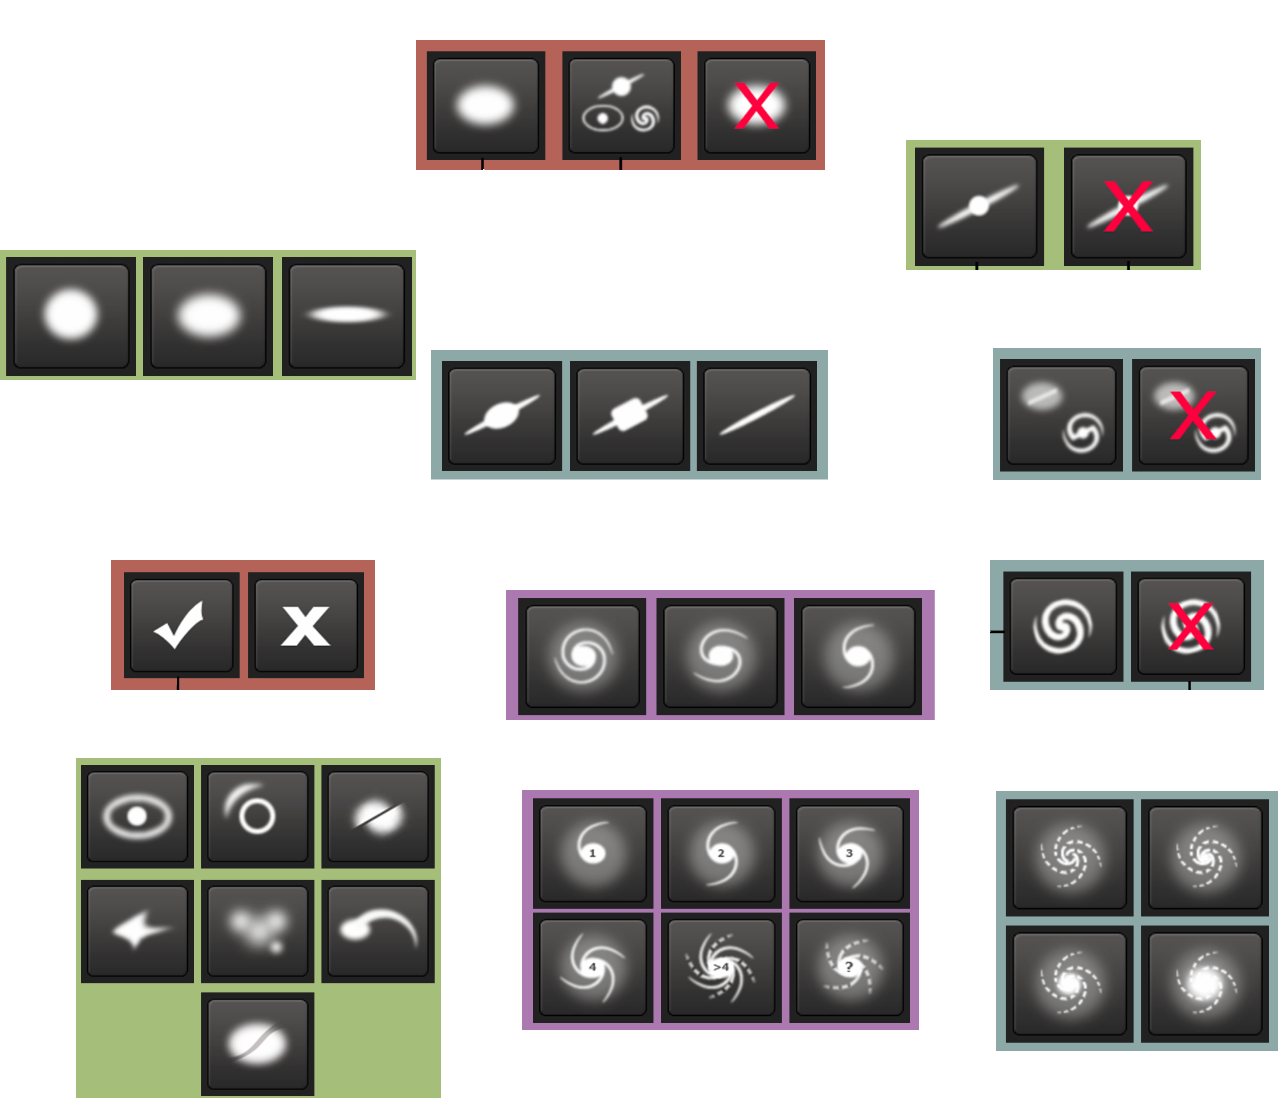

Beraz, hurrengo gauza hauek dakizkigu:

- Ezaugarriduna edo diskoduna bada: Q7ren etiketak ez dira beharrezkoak.
- Leuna bada: Q2-Q5 eta Q9-Q11 etiketak ez dira beharrezkoak.
- Izarra edo artefaktua bada: beste etiketa guztiak ez dira beharrezkoak.

### 1.2.1 Adibidea

Lehen autaz hautatu den irudiaren 0koak ez diren ezaugarriak azpian erakusten dira.

Id = 921229 dun galaxiaren ezaugarriak


,Class1.1,Class1.2,Class1.3,Class2.2,Class3.1,Class3.2,Class4.1,Class4.2,Class5.1,Class5.2,Class6.1,Class6.2,Class7.2,Class7.3,Class8.1,Class8.3,Class8.5,Class10.2,Class10.3,Class11.2,Class11.6
56232,0.463579,0.511503,0.024919,0.511503,0.197432,0.314071,0.245532,0.265971,0.303341,0.208162,0.13935,0.86065,0.441688,0.021891,0.047964,0.076018,0.015368,0.145954,0.099578,0.090742,0.154789


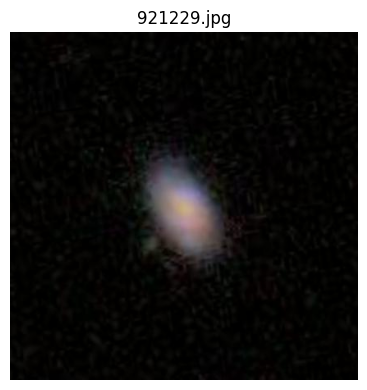

In [ ]:
import pandas as pd

# Pandas zehaztu zutabe guztiak erakusteko
pd.set_option('display.max_columns', None)

# Ebazpenen CSVa kargatu
solutions_dataframe = pd.read_csv(solutions_file_path)

# Lehenengo irudiaren fitxategi-izenaren irudiaren identifikatzailea eskuratu
first_image_filename = sampled_images[0]
first_image_id = int(os.path.splitext(first_image_filename)[0])

# Irudiaren ezaugarrien probabilitateak eskuratu
galaxy_id_str = 'GalaxyID'
image_features = solutions_dataframe[solutions_dataframe[galaxy_id_str] == first_image_id]
image_features = image_features.drop(columns=[galaxy_id_str])

# 0ko zutabeak kendu
image_features = image_features.loc[:, (image_features != 0).any(axis=0)]

# Irudiaren ezaugarrien probabilitateak erakutsi
print(f'Id = {first_image_id} dun galaxiaren ezaugarriak')
display(image_features)

# Lehenengo irudia eskuratu
first_image_path = os.path.join(image_folder, first_image_filename)
first_image = imread(first_image_path)

# Lehenengo irudia erakutsi
plt.figure(figsize=(4, 4))
plt.imshow(first_image)
plt.title(first_image_filename)
plt.axis('off')
plt.tight_layout()
plt.show()

# 2.&nbsp;Datu-multzoa prestatu

Hurrengo urratsa CNNak ikasi al dezan datuak prestatzea da.

## 2.1 Berregingarritasuna bermatu

Blok honen emaitzak berregingarriak izateko ausazko emaitzak ematen dituzten funtzioak deterministak bihurtuko ditugu. Indeterminismoa berreskuratzeko funtzioaren deiaren lehenengo parametroa `False`era aldatu.

In [ ]:
import numpy as np

# Hazia zehaztu berregingarritasuna bermatzeko proiektuan zehar

def mass_set_seeds(mass_set=True, seed=42):
    if not mass_set:
        return None, np.random.default_rng(), None
    rng = np.random.default_rng(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch_generator = torch.Generator(device='cpu')
    torch_generator.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    return seed, rng, torch_generator

# Parametroa False-era aldatu ausazko jokaera berreskuratzeko
seed, rng, torch_generator = mass_set_seeds(True)

## 2.2 Datu-multzoa sortu

Datu-multzoak sortzeko `torch`ek eskaintzen dituen klaseak erabiliko ditugu. `GalaxyDataset` klasea sortzeko `torch.utils.data`-ko `Dataset` klase abstraktua erabiliko da. Klase honek `torch.utils.data`-ko `DataLoader` eta `Subset` klaseek erabiliko dituzten 3 metodo ditu:

- `__init__`: klasea instantziatzeko beharrezko `csv_file` eta `root_dir` parametroak jaso behar ditu, eta hautazkoa den `transform` hirugarren parametro bat. Jasotako `csv` fitxategiak etiketak izan behar dira eta `pandas` erabiltzen da irakurtzeko. Beste bi parametroak gorde besterik ez dira egiten.
- `__len__`: gure datu-multzoaren sarrera kopuura itzultzen du.
- `__getitem__`: iteratzaile bat erabiltzen da irudiaren eta bere etiketen tupla bat itzultzeko.

In [ ]:
from torch.utils.data import Dataset

class GalaxyDataset(Dataset):
    def __init__(self, csv_file, root_dir, transform=None):
        self.labels_dataframe = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.labels_dataframe)

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        img_name = os.path.join(self.root_dir, str(self.labels_dataframe.iloc[idx, 0]) + '.jpg')
        image = imread(img_name)
        labels = self.labels_dataframe.iloc[idx, 1:].values
        labels = torch.from_numpy(labels).float()

        if self.transform:
            image = self.transform(image)

        return image, labels

## 2.3 Datu-laginketa

Ikaskuntza automatikoan, normalki, hainbat eta datu gehiago izan gero eta eredu hobeagoak sortzen dira. Gure kasuan, ordea, baliabide informatiko mugatuak ditugu eta proiektuan zehar erabiliko ditugun irudi kopurua mugatu beharko dugu.

Ausaz 15.000 laginen indizeak lortuko ditugu.

In [ ]:
num_samples = 15000
indices = np.arange(image_count)
sampled_indices = rng.choice(indices, size=num_samples, replace=False)

print(f'Lagindutako indizeak: {sampled_indices}')

Lagindutako indizeak: [ 1120 21889 30825 ... 40305 47657  5495]


Hautatutako langinen indizeak hiru azpimultzoetan banatuko dira `sklearn.model_selection`-eko `train_test_split` erabiliz:

- `train_indices`: entrenamendurako azpimultzoa (datuen % 70a).
- `val_indices`: balioztatzerako azpimultzoa (datuen % 15a).
- `test_indices`: probentzako azpimultzoa (datuen % 15a).

In [ ]:
from sklearn.model_selection import train_test_split

train_indices, temp_indices = train_test_split(sampled_indices, test_size=0.3, random_state=seed, shuffle=True)
val_indices, test_indices = train_test_split(temp_indices, test_size=0.5, random_state=seed, shuffle=True)

print(f'''Entrenamendurako indizeak:   {train_indices}
Balioztatzerako indizeak: {val_indices}
Probentzako indizeak:     {test_indices}''')

Entrenamendurako indizeak:   [44914 11502 11954 ... 42343 60623 51116]
Balioztatzerako indizeak: [29559 57263 17925 ... 42573  5926 32559]
Probentzako indizeak:     [ 8514 33789    54 ... 34234 22646 22738]


Indizeak bananduta gero, `GalaxyDataset` klasea instantziatuko dugu eta `Subset` klasea erabiliz beharrezkoak diren datuen azpimultzoak sortuko ditugu, datu-multzo bat eta indizeen zerrenda bat erabiliz.

*Kontuz! Klasearen bi instanzia erabili behar ditugu, aurrerago bi transformazio segida ezberdin erabili behar ditugu eta. Ezinezkoa izango litzateke instantzia bakarra erabiliz.*

In [ ]:
from torch.utils.data import Subset

train_galaxy_dataset = GalaxyDataset(solutions_file_path, image_folder)
val_test_galaxy_dataset = GalaxyDataset(solutions_file_path, image_folder)

train_set = Subset(train_galaxy_dataset, train_indices)
val_set = Subset(val_test_galaxy_dataset, val_indices)
test_set = Subset(val_test_galaxy_dataset, test_indices)

print(f'Entrenamendurako laginak: {len(train_set)}')
print(f'Balioztatzerako laginak: {len(val_set)}')
print(f'Probentzako laginak: {len(test_set)}')

Entrenamendurako laginak: 10500
Balioztatzerako laginak: 2250
Probentzako laginak: 2250


## 2.4 Irudien aurretratamendua

Lagin guztiei hiru oinarrizko transformazio egingo zaie.

- `transforms.CenterCrop(crop_size)`: irudia moztuko da luzera zehatz bat erabiliz irudiaren erditik neurtuta. Galaxien informazio garrantzitsuena irudien erditik gertu dago. Transformazio hau aplikatuta informazio oso gutxi galduko dugu eta irudi bakoitzaren aztarna txikituko dugu.
- `transforms.Resize((resize_size, resize_size))`: irudiaren bereizmena txikituko dugu. Gure baliabideak mugatuak dira eta transformazio honek CNNak ikasi beharko duen informazio kopurua txikitzen du.
- `transforms.Normalize(mean=mean.tolist(), std=std.tolist())`: pixelen balioak eraldatzen ditu $batezbestekoa \approx 0$ izan dezaten, entrenamendua hobetzeko helburuarekin.

### 2.4.1 Irudiaren mozketa eta bereizmenaren txikitzea

Irudiaren mozketaren tamaina zehazteko kontuan hartu behar dugu irudiak biratzerakoan ertzetan sortzen den zarata ez dela agertu behar bukaerako irudian. Irudi karratu bat biratzean sortzen den kaxa mugatzailearen alde baten luzera honako ekuazioarekin kalkulatzen da:

$$
f\left( l, \theta \right) = \left| l \cdot \cos(\theta) \right| + \left| l \cdot \sin(\theta) \right|
$$

non

\begin{align*}
      & l \gt 0\text{ irudiaren luzera den,} \\
      & \theta\text{ irudiari alpikatutako biraketa den.}
\end{align*}

Honen deribatua kalkulatuz gero eta 0rekin berdinduz gero, ekuazioa maximizatzen duen biraketa anguluaren balioa lortzen dugu: $\theta = 45^{\circ}$.

\begin{equation*}
f'\left( \theta \right) = l \cdot \left( \cos(\theta) - \sin(\theta) \right) \\
l \cdot \left( \cos(\theta) - \sin(\theta) \right) = 0 \\
\cos(\theta) = \sin(\theta) \\
\theta = 45^\circ
\end{equation*}

Maximoa dela egiaztatu dezakegu bigarren deribatua kalkulatuz.

\begin{equation*}
f''(\theta) = l \cdot \left( - \sin(\theta) - \cos(\theta) \right) = -l \cdot \left( \sin(\theta) + \cos(\theta) \right) \\
f''\left( 45^\circ \right) = -l \left( \frac{\sqrt{2}}{2} + \frac{\sqrt{2}}{2} \right) = -l \cdot \sqrt{2} \lt 0
\end{equation*}

Beraz, zarata sortzen ez duen irudiaren mozketa maximoa kalkulatu dezakegu: biraketan sartzen den karratu inskribatu handiena. Karratu honen luzera honela kalkulatzen da (*Pitagorasen teorema* aplikatuz):

$$
inSquareLength = \frac{l \cdot \sqrt{2}}{2}
$$

Irudien tamaina 424koa da, beraz, irudiaren mozketaren tamaina maximoa 300ekoa (gorantz biribildua) izan beharko litzateke. Hautatutako mozketa tamaina 256 izango da eta 128x128ko bereizmena duen irudi batera txikituko da.

In [ ]:
crop_size = 256
resize_size = 128

assert (crop_size - 1 <= image_height * 2**(1/2) / 2) and (crop_size - 1 <= image_width * 2**(1/2) / 2), '[Transform Check] [ERROR]: Mozketa tamaina handiegia da.'
assert (resize_size <= crop_size), '[Transform Check] [ERROR]: Tamaina aldatzeko neurria mozketa tamaina baino txikiagoa izan behar da.'

### 2.4.2 Normalizazioa

Oraingoz gure irudiak `Altuera x Luzera x Kanala` tamainako NumPy-en `ndarrays`-etan gordeta daude, baina guk `Kanala x Altuera x Luzera` tamainako PyTorch-en tentsoreetan behar ditugu. Hau konpontzeko aukera bat irudi bakoitzaren dimentsioak eskuz transposatzea da. Guk, ordea, *torchvision* erabiliko dugu transformazio segida bat aplikatzeko irudiei. Hau erabiliz, segidaren amaieran `transforms.ToTensor()` funtzio dei bat gehituko dugu. Funtzioak dimentsioak transposatuko ditu eta, gainera, balioak normalizatuko ditu `[0, 1]` tartean.

Horrez gain, pixel balioak `0`ren inguru egotea nahi dugu. Hau lortzeko gure entrenamendu multzoaren **batezbestekoa** eta **desbideratze estandarra** balioak kalkulatuko ditugu, gero transformazio segida amaieran aplikatu ahal izateko. Gainera, hemen ezarriko dugu gure lehenengo **hiperparametroa**: `DataLoader`-ek erabiliko duten batch tamaina 128koa izango da.

- Datu-multzoaren batezbestekoa: `[0.0791, 0.0688, 0.0532]`
- Datu-multzoaren desbideratze estandarra: `[0.1182, 0.0997, 0.0837]`


In [ ]:
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

# Batch tamaina Dataloader guztientzako
batch_size = 128

def calculate_dataset_mean_std(dataloader):
    # Hasieratu batezbestekoa eta desbideratze estandarra tentsoreak zeroekin eta 3ko tamainarekin
    mean = torch.zeros(3)
    std = torch.zeros(3)
    total_images = 0

    for images, _ in dataloader:
        # Irudi kopurua lortu eta totala eguneratu
        batch_size = images.size(0)
        total_images += batch_size

        # Reshape images to (B, C, H*W) from (B, C, H, W)
        # Irudien dimentsioask aldatu (B, C, H, W)-tik (B, C, H*W)-ra
        images = images.view(batch_size, images.size(1), -1)

        # Irudi bakoitzaren kanal bakoitzaren batezbestekoa eta desbideratze estandarra pilatu
        mean += images.mean(2).sum(0)
        std += images.std(2).sum(0)

    # Batezbesteko eta desbideratze estandarra kalkulatu
    mean /= total_images
    std /= total_images

    return mean, std

# Aldi baterako dataloader-a sortu batezbestekoa eta desbideratze estandarra kalkulatzeko
temp_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.CenterCrop(crop_size),
    transforms.Resize((resize_size, resize_size)),
    transforms.ToTensor()
])
temp_dataset = GalaxyDataset(solutions_file_path, image_folder, transform=temp_transform)
temp_loader = DataLoader(Subset(temp_dataset, train_indices), batch_size=batch_size)

mean, std = calculate_dataset_mean_std(temp_loader)
print(f"Datu-multzoaren batezbestekoa: {mean}")
print(f"Datu-multzoaren desbideratze estandarra: {std}")

Datu-multzoaren batezbestekoa: tensor([0.0791, 0.0688, 0.0532])
Datu-multzoaren desbideratze estandarra: tensor([0.1182, 0.0997, 0.0837])


### 2.4.3 Transformazioak definitu

Horrez gain, gure entrenamendu laginei beste hainbat transformazio aplikatuko zaizkie *data augmentation* egiteko, gainegokitzapena murrizteko helburuarekin.

- `transforms.RandomRotation(degrees=180, expand=False)`: irudia ausaz biratzen da eta irudia karratu mantentzea zarata (pixel beltzak) gehitzen zaie ertzei.
- `transforms.RandomHorizontalFlip()`: irudia ausaz iraultzen da horizontalki.
- `transforms.RandomVerticalFlip()`: irudia ausaz iraultzen da bertikalki.
- `transforms.ColorJitter(brightness=0.1, contrast=0.1)`: argitasuna eta kontrastea ausaz eguneratzen dira $\pm \% 10$eraino irudi aldakuntzak simulatzeko.

In [ ]:
train_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomRotation(degrees=180, expand=False),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomVerticalFlip(0.5),
    transforms.CenterCrop(crop_size),
    transforms.Resize((resize_size, resize_size)),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean.tolist(), std=std.tolist())
])

print('Entrenamendu transformazioak:')
print(train_transforms)

val_test_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.CenterCrop(crop_size),
    transforms.Resize((resize_size, resize_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean.tolist(), std=std.tolist())
])

print('\nBalidazio/proben transformazioak:')
print(val_test_transforms)

Entrenamendu transformazioak:
Compose(
    ToPILImage()
    RandomRotation(degrees=[-180.0, 180.0], interpolation=nearest, expand=False, fill=0)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    CenterCrop(size=(256, 256))
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=[0.07907750457525253, 0.06875429302453995, 0.05321807041764259], std=[0.11817489564418793, 0.0996929183602333, 0.08373049646615982])
)

Balidazio/proben transformazioak:
Compose(
    ToPILImage()
    CenterCrop(size=(256, 256))
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.07907750457525253, 0.06875429302453995, 0.05321807041764259], std=[0.11817489564418793, 0.0996929183602333, 0.08373049646615982])
)


Transformazio hauek aurretik definitutako datasetei aplikatuko zaie `transform` propietatea zehaztuz.

In [ ]:
train_set.dataset.transform = train_transforms
val_set.dataset.transform = val_test_transforms
# Hau ez da beharrezkoa: val eta test-ek klase instantzia berdina partekatzen dute
# test_set.dataset.transform = val_test_transforms

Jarraian, lehen ausaz hautatutako irudia eta irudi bera baina definitutako transformazioak aplikatuta erakusten dira.

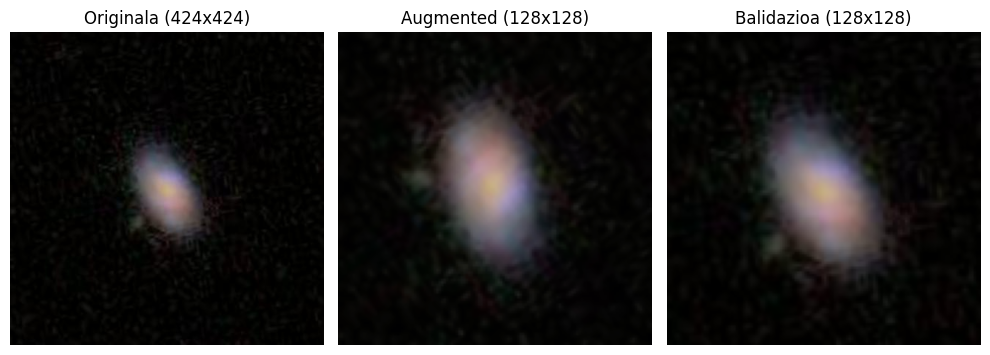

In [ ]:
# Entrenamendu transformazioak ikuskatu lehenengo irudian aplikatuta
transformed_first_image = train_transforms(first_image)

# Desnormalizatu ikuskatzeko
transformed_first_image_denorm = transformed_first_image.clone()
for c in range(3):
    transformed_first_image_denorm[c] = transformed_first_image_denorm[c] * std[c] + mean[c]
# Tentsorea numpy array-era bihurtu eta balioak [0, 1] tartera mugatu floatin point arazoak saihesteko
transformed_first_image__np = transformed_first_image_denorm.permute(1, 2, 0).numpy()
transformed_first_image__np = np.clip(transformed_first_image__np, 0, 1)

# Balidazio/proben transformazioak ikuskatu lehenengo irudian aplikatuta
transformed_first_image_val = val_test_transforms(first_image)

# Desnormalizatu ikuskatzeko
transformed_first_image_val_denorm = transformed_first_image_val.clone()
for c in range(3):
    transformed_first_image_val_denorm[c] = transformed_first_image_val_denorm[c] * std[c] + mean[c]
# Tentsorea numpy array-era bihurtu eta balioak [0, 1] tartera mugatu floatin point arazoak saihesteko
transformed_first_image_val__np = transformed_first_image_val_denorm.permute(1, 2, 0).numpy()
transformed_first_image_val__np = np.clip(transformed_first_image_val__np, 0, 1)

# Canvasa sortu
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(10, 5))

# Originala trazatu
ax1.imshow(first_image)
ax1.set_title(f"Originala ({first_image.shape[0]}x{first_image.shape[1]})")
ax1.axis('off')

# Entrenamendu transformazioa trazatu
ax2.imshow(transformed_first_image__np)
ax2.set_title(f"Augmented ({transformed_first_image__np.shape[0]}x{transformed_first_image__np.shape[1]})")
ax2.axis('off')

# Balidazio transformazioa trazatu
ax3.imshow(transformed_first_image_val__np)
ax3.set_title(f"Balidazioa ({transformed_first_image_val__np.shape[0]}x{transformed_first_image_val__np.shape[1]})")
ax3.axis('off')

plt.tight_layout()
plt.show()

## 2.5 Datuak kargatu

CNNari datuak batch txikietan emateko PyTorch-en `DataLoader` klasea erabiliko dugu. Datu azpimultzo `Subset` bakoitzak `DataLoader` bat erabiliko du.

- `DataLoader` guztiek mini-batch tamaina berdina erabiliko dute: 128 (2.4.2 atalean zehaztu da).
- Entrenamenduko `DataLoader`-ak datuak epoch bakoitzean berriz nahastuko ditu, ereduak datuak hobeto orokortzeko gaitasuna hobetzeko. Nahasketa honek berregingarritasuna mantendu ahal izateko, torch-en `Generator` objektu bat sortu da lehen eta hazi determinista bat jarri zaio.

In [ ]:
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, generator=torch_generator)
val_loader = DataLoader(val_set, batch_size=batch_size)
test_loader = DataLoader(test_set, batch_size=batch_size)

# 3.&nbsp;CNNaren inplementazioa

Atal honetan gure CNNa sortzeko beharrezko den guztia inplementatuko da. Gure CNNaren arkitektura **ResNet** arkitekturan oinarrituko da, eta *Bottleneck* arkitektura erabiliko du hondar-blokerako.

## 3.1 Hondar-blokea

Erabiliko den hondar-blokea hiru konboluzio bloke sekuentzialek osatzen dute. Bloke bakoitzak konboluzioa egiten dute, eta jarraian, normalizazioa eta ReLU aktibazio funtzio bat exekutatzen dute ez-lineartasuna gehitzeko. Azkeneko blokean, ordea, aktibazio funtzioa beranduago gehitzen zaio.

Konboluzio bloke sekuentziak bakoitzean, ondorengo konboluzioak exekutatzen dira:

1. Kanalen dimentsioa murrizten du eta dimentsio espazialak ere murrizten ditu `stride` pasatzen bazaio.
    - *Parametroak:* `in_channels` sarrera kanalak, `1x1` tamainako `out_channels` geruzak, pausoa `stride` eta betegarria `0`.
2. `3x3` tamainako konboluzioa aplikatzen du dimentsio espazialak aldatu gabe.
    - *Parametroak:* `out_channels` sarrera kanalak, `3x3` tamainako `out_channels` geruzak, pausoa `1` eta betegarria `1`.
3. Kanalen dimentsioa berriz atzera handitzen du.
    - *Parametroak:* `out_channels` sarrera kanalak, `1x1` tamainako `4 * out_channels` geruzak, pausoa `1` eta betegarria `0`.

Konboluzio eragiketa bakoitzaren ondoren normalizazioa exekutatzen da. Erabiltzen den `BatchNorm2d` moduluak jada baditu ikasten diren $\gamma$ eta $\beta$ parametro propioak. Beraz, konboluzio geruzek ez dute alborapen propio bat izango.

$$
y = \frac{x - \text{E} \left[ x \right]}{\sqrt{\text{Var} \left[ x \right] + \epsilon}} * \gamma + \beta
$$

Sekuentziako azkeneko konboluzio blokea exekutatu ondoren, hondar-blokea gehitu egiten da aurreko blokearen irteerara. Hondar-bloke hau laburbide identitatea da sarrera eta irteera dimentsioak edo dimentsio espazialak ez badira aldatzen; aldatzen badira, identitatea lehenengo laburbide funtzio batetik igarotzen da azkeneko blokera gehitu aurretik.

In [ ]:
from torch.nn import Module, Sequential, Conv2d, BatchNorm2d, ReLU

class ResidualBottleneckBlock(Module):

    # Irteerako kanalaren dimentsioa zenbat handitzen den zehazten duen faktorea ezarri
    dimension_increase = 4

    def __init__(self, in_channels, out_channels, stride=1, shortcut=None):
        super(ResidualBottleneckBlock, self).__init__()

        # Lehenengo konboluzio-blokea: 1x1eko konboluzioa kanalen dimentsioak eta dimentsio espazialak (stride > 1 bada) txikitzeko
        self.conv1_block = Sequential(
            Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
            BatchNorm2d(out_channels),
            ReLU(inplace=True)
        )

        # Bigarren konboluzio-blokea: 3x3ko konboluzioko prozesatze geruza nagusia, dimentsio espazialak mantenduz
        self.conv2_block = Sequential(
            Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding='same', bias=False),
            BatchNorm2d(out_channels),
            ReLU(inplace=True)
        )

        # Hirugarren konboluzio-blokea: 1x1 konboluzioa kanalek dimentsioak berreskuratzeko
        self.conv3_block = Sequential(
            Conv2d(out_channels, out_channels * self.dimension_increase, kernel_size=1, stride=1, bias=False),
            BatchNorm2d(out_channels * self.dimension_increase)
        )

        self.relu = ReLU(inplace=True)
        self.shortcut = shortcut

    def forward(self, x):
        # Hondar-blokea hasieratu laburbide identitatea gisa
        residual_connection = x

        out = self.conv1_block(x)
        out = self.conv2_block(out)
        out = self.conv3_block(out)

        # Laburbide funtzioa aplikatu dimentsioak handitzen direnean
        if self.shortcut:
            residual_connection = self.shortcut(x)

        out += residual_connection
        out = self.relu(out)

        return out

## 3.2 Eredua

Hondar-blokea eraiki ondoren, hurrengo pausua CNN modulua sortzea da. Klaseak hiru metodo izango ditu:

- `__init__`: bost geruza nagusi eta sailkapen geruzak gordetzen ditu, eta pisuak eta alborapenak hasieratzen ditu.
    - `3` sarrera kanal `64` kanaletara transformatzen dituen konboluzioa, `7x7`ko iragazkia erabiliz `2`ko pausoa eta `3`ko betegarria duena (dimentsio espazialak erdira murrizteko). Ondoren, honakoak aplikatzen dira: normalizazioa, ReLU aktibazio funtzioa eta `3x3`ko max pooling azpilaginketa-geruza `2`ko pausoa eta `1`eko betegarria duena (dimentsio espazialak erdira murrizteko).
    - `64` irteera kanal dituzten `3` Bottleneck-bloke sorta, lehenengo blokeko lehenengo konboluzio-geruzan `1`eko pausoa duena.
    - `128` irteera kanal dituzten `4` Bottleneck-bloke sorta, lehenengo blokeko lehenengo konboluzio-geruzan `2`ko pausoa duena.
    - `256` irteera kanal dituzten `6` Bottleneck-bloke sorta, lehenengo blokeko lehenengo konboluzio-geruzan `2`ko pausoa duena.
    - `512` irteera kanal dituzten `3` Bottleneck-bloke sorta, lehenengo blokeko lehenengo konboluzio-geruzan `2`ko pausoa duena.
    - Sailkapen geruzak:
        - Azkeneko bottleneck-blokeak emandako `2048` kanalei average pooling-a aplikatzen zaio `1x1` tamainako geruzak lortzeko.
        - Galdera bakoitzarentzako guztiz konektatutako geruza bat, `2048` sarrera kanal galdera bakoitzak izan ditzakeen erantzun kopurura murrizten duena.
    - Konboluzio-geruzen eta guztiz konektatutako geruzen pisuak hasieratzeko Kaiming edo He hasieraketa erabiliko da, `torch.nn.init`-eko `kaiming_normal_` funtzioa erabiliz. Normalizazio-geruzen pisuak `1`ean eta normalizazio-geruzen eta guztiz konektatutako geruzen alborapenak `0`an hasieratzen dira.
    
- `_make_block`: `num_blocks` kopuruko bottleneck-bloke sorta sortzen du. Kanalak edo dimentsio espazialak aldatzen badira sortako lehenengo blokeak laburbide funtzio berezi bat beharko du. Hala bada, laburbide funtzioa `self.in_channels` sarrera kanal `out_channels * block.dimension_increase` irteera kanaletara bihurtzen dituen konboluzio gisa definitzen da, `1x1` tamainako iragazkia eta `first_block_layer_stride` pausoa erabiliz, eta normalizazioa aplikatzen zaio gero. Azkenik, gainontzeko blokeak sortu aurretik, `self.in_channels` balioa `out_channels * block.dimension_increase`-ra eguneratzen da.
- `forward`: sarrera geruza nagusi guztietatik eta sailkapen geruzatik igarotzen du. Sailkapen geruza partekatuaren irteera (features) `11` guztiz konektatutako geruza guztietara pasatzen da. Lehenengo guztiz konektatutako geruzaren irteera `softmax` aktibazio funtziora igarotzen da probabilitate guztien batura `1` izateko, eta gainontzeko geruzen irteerak normalizatu egiten dira `sigmoid` aktibazio funtzioetara pasatuz eta dagozkien *Q1*eko iragarpenaren probabilitateekin murriztuz.
    - *Q7*: `q1_smooth`-k murriztua (Class1.1).
    - *Q2*, *Q3*, *Q4*, *Q5*, *Q9*, *Q10*, *Q11*: `q1_features`-k murriztua (Class1.2).
    - *Q6*, *Q8*: `1 - q1_star`-k murriztua (ez Class1.3).

Aurreko atalean azaldu den bezala, konboluzio guztien ondoren normalizazioa exekutatzen da. Beraz, konboluzio geruza guztien alborapenak kendu egiten dira.

In [ ]:
from torch import sigmoid
from torch.nn import AdaptiveAvgPool2d, Flatten, MaxPool2d, Linear
from torch.nn.init import constant_, kaiming_normal_
from torch.nn.functional import softmax

class GalaxyCNN(Module):
    def __init__(self, block=ResidualBottleneckBlock, blocks_per_layer=[3, 4, 6, 3]):
        super(GalaxyCNN, self).__init__()

        # Hasierako sarrera kanal kopurua
        self.in_channels = 64

        # Hasierako konboluzio-geruza dimentsio espazialak murrizteko
        self.conv1 = Sequential(
            Conv2d(3, self.in_channels, kernel_size=7, stride=2, padding=3, bias=False),
            BatchNorm2d(self.in_channels),
            ReLU(inplace=True),
            MaxPool2d(kernel_size=3, stride=2, padding=1)
        )

        # Hondar-bloke sortak
        self.conv2_x = self._make_block(block, 64, blocks_per_layer[0], 1)
        self.conv3_x = self._make_block(block, 128, blocks_per_layer[1], 2)
        self.conv4_x = self._make_block(block, 256, blocks_per_layer[2], 2)
        self.conv5_x = self._make_block(block, 512, blocks_per_layer[3], 2)

        # Sailkapen burukoa (pooling eta flatten, iragarpenak beranduago datoz)
        self.classifier = Sequential(
            AdaptiveAvgPool2d((1, 1)),
            Flatten(1)
        )

        # Ezaugarrien sarrera dimentsioak hondar-blokeen ondoren
        feature_dim = 512 * block.dimension_increase

        # Buruko ezberdinak galdera bakoitzarentzat
        self.q1_head = Linear(feature_dim, 3)  # Q1: Leuna/Ezaugarriduna/Izarra
        self.q2_head = Linear(feature_dim, 2)  # Q2: Ertza ikusgai bai/ez
        self.q3_head = Linear(feature_dim, 2)  # Q3: Barra bai/ez
        self.q4_head = Linear(feature_dim, 2)  # Q4: Espirala bai/ez
        self.q5_head = Linear(feature_dim, 4)  # Q5: Erdiko tontorra nabarmen (4 aukera)
        self.q6_head = Linear(feature_dim, 2)  # Q6: Arraroa bai/ez
        self.q7_head = Linear(feature_dim, 3)  # Q7: Biribila (3 aukera)
        self.q8_head = Linear(feature_dim, 7)  # Q8: Ezaugarri arraroa (7 aukera)
        self.q9_head = Linear(feature_dim, 3)  # Q9: Tontor itxura ertza ikusgai denean (3 aukera)
        self.q10_head = Linear(feature_dim, 3) # Q10: Espiralen gertutasuna (3 aukera)
        self.q11_head = Linear(feature_dim, 6) # Q11: Beso espiral kopurua (6 aukera)

        # Pisuak hasieratu
        for m in self.modules():
            if isinstance(m, Conv2d):
                kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, BatchNorm2d):
                if m.weight is not None:
                    constant_(m.weight, 1)
                if m.bias is not None:
                    constant_(m.bias, 0)
            elif isinstance(m, Linear):
                kaiming_normal_(m.weight, nonlinearity='relu')
                if m.bias is not None:
                    constant_(m.bias, 0)

    def _make_block(self, block, out_channels, num_blocks, first_block_layer_stride):
        # Erabaki laburbidea beharrezkoa den dimentsioak bat etortzeko
        shortcut = None
        if first_block_layer_stride != 1 or self.in_channels != out_channels * block.dimension_increase:
            shortcut = Sequential(
                Conv2d(
                    self.in_channels,
                    out_channels * block.dimension_increase,
                    kernel_size=1,
                    stride=first_block_layer_stride,
                    bias=False
                ),
                BatchNorm2d(out_channels * block.dimension_increase)
            )

        # Blokeak gordetzeko zerrenda hutsa
        layers = []

        # Geruzan dimentsioak alda ditzakeen lehenengo blokea
        block_1 = block(self.in_channels, out_channels, first_block_layer_stride, shortcut)
        layers.append(block_1)

        # in_channels eguneratu hurrengo blokeentzat
        self.in_channels = out_channels * block.dimension_increase

        # Gainontzeko dimentsio aldaketarik gabeko blokeak
        for _ in range(1, num_blocks):
            block_x = block(self.in_channels, out_channels)
            layers.append(block_x)

        return Sequential(*layers)

    def forward(self, x):
        # Modulu partekatu nagusien exekuzioa
        x = self.conv1(x)
        x = self.conv2_x(x)
        x = self.conv3_x(x)
        x = self.conv4_x(x)
        x = self.conv5_x(x)
        features = self.classifier(x)

        # Q1: Beti iragarri (softmax gehiketa=1 lortzeko)
        q1_logits = self.q1_head(features)
        q1 = softmax(q1_logits, dim=1)
        q1_smooth = q1[:, 0:1]   # Class1.1
        q1_features = q1[:, 1:2] # Class1.2
        q1_star = q1[:, 2:3]     # Class1.3

        # Q2: Ertza ikusgai (bakarrik for ezaugarriduna/diskoduna galaxientzat)
        q2_raw = sigmoid(self.q2_head(features))
        q2 = q2_raw * q1_features  # Scale by features probability

        # Q3: Barra (bakarrik for ezaugarriduna/diskoduna galaxientzat)
        q3_raw = sigmoid(self.q3_head(features))
        q3 = q3_raw * q1_features

        # Q4: Espirala (bakarrik for ezaugarriduna/diskoduna galaxientzat)
        q4_raw = sigmoid(self.q4_head(features))
        q4 = q4_raw * q1_features

        # Q5: Erdiko tontorra nabarmen (bakarrik for ezaugarriduna/diskoduna galaxientzat)
        q5_raw = sigmoid(self.q5_head(features))
        q5 = q5_raw * q1_features

        # Q6: Arraroa (leunetik edo ezaugarridunetik etorri daiteke, baina ez izarretik)
        not_star = 1 - q1_star
        q6_raw = sigmoid(self.q6_head(features))
        q6 = q6_raw * not_star

        # Q7: Biribila (bakarrik galaxia leunentzat)
        q7_raw = sigmoid(self.q7_head(features))
        q7 = q7_raw * q1_smooth

        # Q8: Ezaugarri arraroa (leunetik edo ezaugarridunetik etorri daiteke, baina ez izarretik)
        q8_raw = sigmoid(self.q8_head(features))
        q8 = q8_raw * not_star

        # Q9: Tontor itxura ertza ikusgai denean (bakarrik for ezaugarriduna/diskoduna galaxientzat)
        q9_raw = sigmoid(self.q9_head(features))
        q9 = q9_raw * q1_features

        # Q10: Espiralen gertutasuna (bakarrik for ezaugarriduna/diskoduna galaxientzat)
        q10_raw = sigmoid(self.q10_head(features))
        q10 = q10_raw * q1_features

        # Q11: Beso espiral kopurua (bakarrik for ezaugarriduna/diskoduna galaxientzat)
        q11_raw = sigmoid(self.q11_head(features))
        q11 = q11_raw * q1_features

        # Iragarpen guztiak kateatu ordena egokian
        # Ordena: Q1(3), Q2(2), Q3(2), Q4(2), Q5(4), Q6(2), Q7(3), Q8(7), Q9(3), Q10(3), Q11(6)
        # Indizeak: 0-2, 3-4, 5-6, 7-8, 9-12, 13-14, 15-17, 18-24, 25-27, 28-30, 31-36
        # Klaseak: Class1.1-Class1.3, Class2.1-Class2.2, Class3.1-Class3.2, Class4.1-Class4.2,
        #          Class5.1-Class5.4, Class6.1-Class6.2, Class7.1-Class7.3, Class8.1-Class8.7,
        #          Class9.1-Class9.3, Class10.1-Class10.3, Class11.1-Class11.6
        output = torch.cat([q1, q2, q3, q4, q5, q6, q7, q8, q9, q10, q11], dim=1)

        return output

testcnn = GalaxyCNN()
# Default to CPU if using DirectML. Summary doesn't work with DirectML.
# DirectML erabiliz gero CPUra aldatu. Summary-k ez du funtzionatzen DirectMLekin
testcnn.to("cpu" if not device in ['cuda', 'cpu'] else device)

print('GalaxyCNN eredua:')
print(testcnn)

GalaxyCNN eredua:
GalaxyCNN(
  (conv1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  )
  (conv2_x): Sequential(
    (0): ResidualBottleneckBlock(
      (conv1_block): Sequential(
        (0): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (conv2_block): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same, bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (conv3_block): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=

`torchsummary`ko `summary` exekutatu dezakegu CNNeko geruza guztiak zerrendatzeko, bakoitzaren irteeraren itxurarekin eta parametro ikasgai kopuruarekin. Ereduak guztira 23.583.845 parametro ikasgai eta 185 geruza ditu.

In [ ]:
from torchsummary import summary

print('Ereduaren laburpena:')
summary(testcnn, input_size=(3, resize_size, resize_size))

Ereduaren laburpena:
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 64, 64]           9,408
       BatchNorm2d-2           [-1, 64, 64, 64]             128
              ReLU-3           [-1, 64, 64, 64]               0
         MaxPool2d-4           [-1, 64, 32, 32]               0
            Conv2d-5           [-1, 64, 32, 32]           4,096
       BatchNorm2d-6           [-1, 64, 32, 32]             128
              ReLU-7           [-1, 64, 32, 32]               0
            Conv2d-8           [-1, 64, 32, 32]          36,864
       BatchNorm2d-9           [-1, 64, 32, 32]             128
             ReLU-10           [-1, 64, 32, 32]               0
           Conv2d-11          [-1, 256, 32, 32]          16,384
      BatchNorm2d-12          [-1, 256, 32, 32]             512
           Conv2d-13          [-1, 256, 32, 32]          16,384
      BatchNorm2d-

# 4.&nbsp;Entrenamendua eta balidazioa

Gure ereduaren instantzia bat sortuz hasiko gara eta erabilgarri dagoen gailuari ezarriko diogu.

In [ ]:
model = GalaxyCNN()
model.to(device)

GalaxyCNN(
  (conv1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  )
  (conv2_x): Sequential(
    (0): ResidualBottleneckBlock(
      (conv1_block): Sequential(
        (0): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (conv2_block): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same, bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (conv3_block): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1)

### 4.1 Hiperparametroak

Eredua entrenatuko dugu `0,001`eko hasierako ikaskuntza-tasarekin `100` epochen zehar. Horrez gain, `10` epocheko pazientzia zehaztuko da gelditze goiztiarrerako.

In [ ]:
learning_rate = 1e-3
epochs = 100
patience = 10

### 4.2 Teknikak

Jarraian azaltzen diren teknikak erabiliko dira gure ereduaren entrenamenduaren eta balidazioan zehar:

- Galera funtzioa (criterion): `torch.nn`-ko `MSELoss` erabiltzen da lortutako eta benetako balioaren errorea kalkulatzeko. Iragarritako balioaren eta benetako balioaren arteko batez besteko errore kuadratikoa kalkulatzen du.
- Optimizatzailea: `troch.optim`eko `Adam` erabiltzen da ereduaren parametroak optimizatuz galera hobetzeko. `0,0005`eko pisuen gainbera aplikatzen zaio gainegokitzapena murrizteko, L2-ren antzeko penalizazio termino bat gehitzen duena parametroak eguneratzeko.
- Ikaskuntza-tasaren planifikatzailea: `torch.optim.lr_scheduler`ko `ReduceLROnPlateau` erabiltzen da ikaskuntza-tasa murrizteko balidazio-galera gehiago ez denean hobetzen.
- Gelditze goiztiarra: Gainegokitzapena saihesten du eta entrenamendua geldituko du ereduak hobetzeari uzten dionean.

In [ ]:
from torch.nn import MSELoss
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

loss_fn = MSELoss()
optimizer = Adam(model.parameters(), lr=learning_rate, weight_decay=5e-4)
scheduler = ReduceLROnPlateau(optimizer, 'min', factor=0.1, patience=int(patience/2))

### 4.3 Entrenamendu begizta

Eredua entrenatu ahal izateko falta den azkeneko pausua entrenamendu eta balidazio begiztak osatzea da.

Epoch bakoitzean, `model.train()` exekutatzen da ereduaren `training` propietatea `True`ra aldatzeko. Honek hainbat moduluen portaera aldatzen: adibidez, entrenamendu moduan, `BatchNorm2d`ek batezbestekoa eta desbideratze estandarra birkalkulatuko ditu. Honen ondoren, datuak `DataLoader`etik eskuratzen dira, erabilgarri dagoen gailuan zehazten dira eta iteratu egiten da.

Iterazio bakoitzean sarrera datuak (transformatutako irudi pixelak) ereduari pasatzen zaio eta honen iragarpen bat egiten du. Iragarpen hau aurresan balioekin konparatzen da galera-funtzioa (*criterion*) erabiliz zehazteko zenbateko "okerra" den ereduaren iragarpena. Ondoren, *backpropagation* exekutatzen da: aurreko iterazioan kalkulatutako gradienteak ezabatzen dira oraingo iterazioarekin ez pilatzeko `optimizer.zero_grad()` erabiliz, gradiente berriak kalkulatzen dira parametro ikasgai guztientzako uneko galera erabiliz `loss.backward()` deituz, eta gradiente berriak erabiliz parametro ikasgaiak eguneratzen dira galera murrizten saiatzeko `optimizer.step()` erabiliz. Azkenik, iterazio honen galera pilatu egiten da, iragarritako eta aurresan balioak gorde egiten dira, eta batcharen galera eta doitasuna kalkulatzen dira.

Batch guztiak iteratu ondoren epockaren galera eta doitasuna kalkulatzen dira. Galera kalkulatzeko pilatutako galera datu-multzoaren tamainarekin zatitzen da. Doitasuna kalkulatzeko ereduaren iragarritako eta aurresan balioen arteko MAE (Mean Absolute Error) kalkulatzen da.

In [ ]:
def training_loop(dataloader, model, loss_fn, optimizer, device):
    model.train()
    size = len(dataloader.dataset)
    running_loss = 0
    all_predictions = []
    all_true_labels = []

    for batch, (X, y) in enumerate(dataloader):
        X = X.to(device)
        y = y.to(device)

        # Iragarpena eta galera kalkulatu
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Batcharen galera pilatu
        running_loss += loss.item() * X.size(0)

        # Iragarpenak eta aurresan balioak pilatu balio jarraitu gisa
        all_predictions.append(pred.detach().cpu().numpy())
        all_true_labels.append(y.cpu().numpy())

        if batch % 8 == 0:
            loss, current = loss.item(), batch * len(X)
            print(f"batch galera: {loss:>7f}  [{current:>5d}/{size:>5d}]")

    # Epoch galera kalkulatu
    epoch_loss = running_loss / size

    # Batchak kateatu
    all_predictions = np.concatenate(all_predictions, axis=0)
    all_true_labels = np.concatenate(all_true_labels, axis=0)

    # MAE kalkulatu (Mean Absolute Error)
    epoch_accuracy = np.abs(all_predictions - all_true_labels).mean()

    return epoch_loss, epoch_accuracy

### 4.4 Balidazio begizta

Entrenamendu begiztan egin den antzeran, lehenik `model.eval()` exekutatzen da epoch guztietan ereduko `training` propietatea `False`era zehazteko. Jarraian, gradienteak kalkulatzeko beharrezkoa den konputazio grafoaren sorketa ezeztatzen da `torch.no_grad()` exekutatuz.

Balidazio begiztako iterazio guztiek entrenamendu begiztako antzeko iterazioak egiten dute: iragarpena egin, galera kalkulatu eta pilatu, eta iragarritako eta aurresan balioak pilatu. Ez ditugu aldatu nahi ereduaren pisuak, beraz, backpropagationa ez da exekutatzen.

Azkenik, batch guztiak iteratu ondoren, galera eta doitasuna entrenamendu begizan bezala kalkulatzen dira.

In [ ]:
def validation_loop(dataloader, model, loss_fn, device):
    model.eval()
    size = len(dataloader.dataset)
    running_loss = 0
    all_predictions = []
    all_true_labels = []

    with torch.no_grad():
        for X, y in dataloader:
            X = X.to(device)
            y = y.to(device)

            # Iragarpena eta galera kalkulatu
            pred = model(X)
            loss = loss_fn(pred, y)

            # Batcharen galera pilatu
            running_loss += loss.item() * X.size(0)

            # Iragarpenak eta aurresan balioak pilatu balio jarraitu gisa
            all_predictions.append(pred.detach().cpu().numpy())
            all_true_labels.append(y.cpu().numpy())

    # Epoch galera kalkulatu
    epoch_loss = running_loss / size

    # Batchak kateatu
    all_predictions = np.concatenate(all_predictions, axis=0)
    all_true_labels = np.concatenate(all_true_labels, axis=0)

    # MAE kalkulatu (Mean Absolute Error)
    mae = np.abs(all_predictions - all_true_labels).mean()

    return epoch_loss, mae

## 4.5 Entrenamenduaren hasiera

Jada eredua entrenatzen hasteko dena dugu! Entrenamenduak honakoa egingo du:

- Entrenamendu begizta exekutatu eta metrikak gorde.
- Balidazio begizta exekutatu eta metrikak gorde.
- Uneko ikaskuntza-tasa ikuskatu.
- Gelditze goiztiarra begiratu. Eredua hobetzen denean ereduaren hiperparametroak memorian gordeko dira eta ereduaren kopia bat diskoan gordeko da.
- Ikaskuntza-tasa eguneratu planifikatzaileak beharrezkoa dela uste badu.
- Entrenamendua gelditu pazientzia gainditu bada.

In [ ]:
import time
import copy

output_folder = 'out'
os.makedirs(output_folder, exist_ok=True)
best_model_filename = 'bestmodel.pth'
best_model_path = os.path.join(output_folder, best_model_filename)

train_losses, train_accuracies, val_accuracies, val_losses  = [], [], [], []

start = time.time()
best_model_wts = copy.deepcopy(model.state_dict())
best_val_loss = float('inf')
epochs_no_improve = 0

for t in range(epochs):
    print(f"Epoch {t+1}/{epochs}\n{'-'*50}")

    # Entrenamendu fasea
    train_loss, train_acc = training_loop(train_loader, model, loss_fn, optimizer, device)
    print(f'\nEntrenamendu Errorea:\n Galera: {train_loss:>8f}, Doitasuna (MAE): {train_acc:>0.4f}\n')

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # Balidazio fasea
    val_loss, val_acc = validation_loop(val_loader, model, loss_fn, device)
    print(f"Balidazio Errorea:\n Galera: {val_loss:>8f}, Doitasuna (MAE): {val_acc:>0.4f}\n")

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    # Ikaskuntza-tasa ikuskatu
    current_lr = scheduler.get_last_lr()
    print(f"Uneko IT: {current_lr}\n")

    # Gelditze goiztiarra
    if val_loss < best_val_loss:
        old_best_val_loss = best_val_loss
        best_val_loss = val_loss
        epochs_no_improve = 0
        # ereduaren pisuak kopiatu
        best_model_wts = copy.deepcopy(model.state_dict())
        # eredua gorde
        torch.save(model, best_model_path)
        print(f'Balidazio galera hobetu da. {old_best_val_loss}tik {best_val_loss}ra murriztu da.\n')
    else:
        epochs_no_improve += 1
        print(f'Balidazio galera ez da hobetu. {epochs_no_improve} epoch hobekuntza gabe.\n')

    # Ikaskuntza-tasa pausoa
    scheduler.step(val_loss)

    if epochs_no_improve == patience:
        print(f'Gelditze goiztiarra! Hobekuntzarik ez {patience} epochetan.')
        break

print("Amaituta!")

end = time.time()
elapsed_time = end - start
print(f'Entrenamendu denbora: {elapsed_time // 60:.0f}m {elapsed_time % 60:.0f}s')

best_val_loss_idx = val_losses.index(best_val_loss)
print(f'Balidazio galera hoberena: {best_val_loss:4f} {best_val_loss_idx+1}. epochean [{val_accuracies[best_val_loss_idx]:.4f}ko doikuntzarekin (MAE)]')

best_val_acc_idx = val_accuracies.index(min(val_accuracies))
print(f'Balidazio doikuntza hoberena (MAE): {min(val_accuracies):.4f} {best_val_acc_idx+1}. epochean [{val_losses[best_val_acc_idx]:.4f}ko galerarekin]')

# Pisuak best_val_loss-ra berreskuratu
model.load_state_dict(best_model_wts)

Epoch 1/100
--------------------------------------------------
batch galera: 0.116028  [    0/10500]
batch galera: 0.056312  [ 1024/10500]
batch galera: 0.055750  [ 2048/10500]
batch galera: 0.057284  [ 3072/10500]
batch galera: 0.049331  [ 4096/10500]
batch galera: 0.058095  [ 5120/10500]
batch galera: 0.035319  [ 6144/10500]
batch galera: 0.025998  [ 7168/10500]
batch galera: 0.025544  [ 8192/10500]
batch galera: 0.024194  [ 9216/10500]
batch galera: 0.028099  [10240/10500]

Entrenamendu Errorea:
 Galera: 0.045569, Doitasuna (MAE): 0.1176

Balidazio Errorea:
 Galera: 0.031383, Doitasuna (MAE): 0.1129

Uneko IT: [0.001]

Balidazio galera hobetu da. inftik 0.031383460405800076ra murriztu da.

Epoch 2/100
--------------------------------------------------
batch galera: 0.028269  [    0/10500]
batch galera: 0.026552  [ 1024/10500]
batch galera: 0.026872  [ 2048/10500]
batch galera: 0.022870  [ 3072/10500]
batch galera: 0.025257  [ 4096/10500]
batch galera: 0.019756  [ 5120/10500]
batch g

<All keys matched successfully>

Gure `GalaxyCNN` ereduaren entrenamenduak 2h 35min iraun du. Lortutako balidazio galera hoberena `0,00999` izan da `97`. epochean. Lortutako balidazio doikuntza hoberena `0,063` izan da `100`. epochean.

Marraztu ditzagun epoch bakoitzeko metrikak galera eta doikuntzen ikaskuntza kurbak ikuskatzeko, bai entrenamenduko datu-multzoarentzat, bai balidazioaren datu-multzoarentzat.

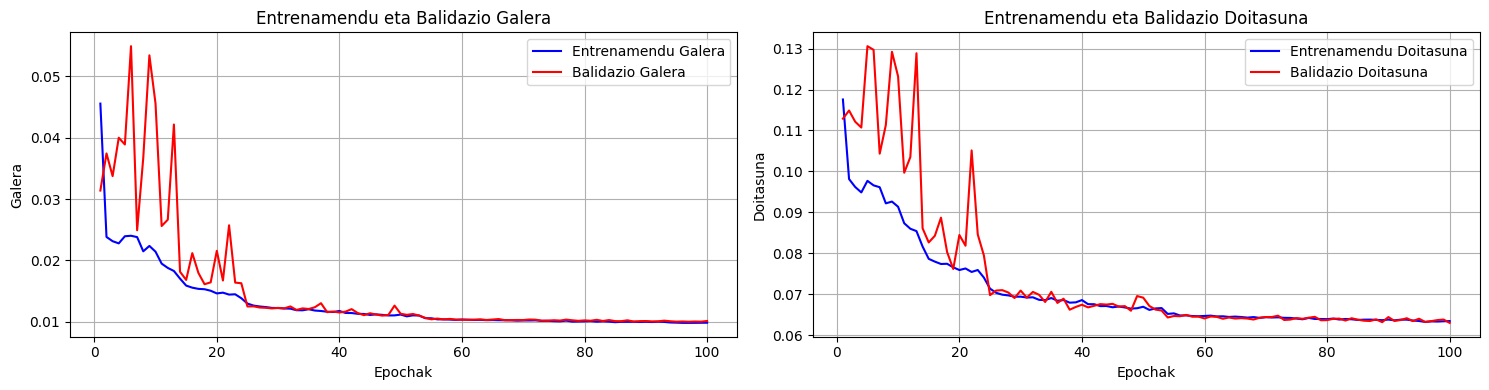

In [ ]:
def plot_metrics(train_losses, val_losses, train_accuracies, val_accuracies):
    epochs_range = range(1, len(train_losses) + 1)

    plt.figure(figsize=(15, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, train_losses, label='Entrenamendu Galera', color='blue')
    plt.plot(epochs_range, val_losses, label='Balidazio Galera', color='red')
    plt.title('Entrenamendu eta Balidazio Galera')
    plt.xlabel('Epochak')
    plt.ylabel('Galera')
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, train_accuracies, label='Entrenamendu Doitasuna', color='blue')
    plt.plot(epochs_range, val_accuracies, label='Balidazio Doitasuna', color='red')
    plt.title('Entrenamendu eta Balidazio Doitasuna')
    plt.xlabel('Epochak')
    plt.ylabel('Doitasuna')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_metrics(train_losses, val_losses, train_accuracies, val_accuracies)

Gelditze goiztiarrak ez du entrenamendua gelditu. Ikusi dezakegu balidazio sortak tontor batzuk izan dituela, baina entrenamendu sortarekin konbergitzen hasten da 20. epochean. Bi sortetan galera murriztea eta doitasuna handitzea lortu dugu 50. epoch arte, non konbergitzen hasi dira. Une honetan $\approx 0.01$eko galera eta $\% 6,5$eko doikuntza (MAE) lortu ditugu, eta ondorengo epochetan leuntzen jarraitu du. Ereduak ondo orokortu du balidazio sorta gainegokitzapenik gabe eta doitasun ona mantendu entrenamenduan eta balidazioan.

## 4.6 Eredua gorde

Eredua Google Drive-ko karpeta batean gordeko dugu Google Colab-eko runtime-a amaitzean aurrerapena ez galtzeko (Colab-en exekutatzen ari bagara).

In [ ]:
import shutil
from datetime import datetime

try:
    from google.colab import drive
    drive.mount('/content/drive')
    save_dir = '/content/drive/MyDrive/galaxy_cnn_checkpoint'
# Import-ak errorea ematen badu ez gaude Colab-eko notebook batean, lokalean baizik.
# Hala bada, checkpoints karpeta bat zehaztu proiektuaren direktorioan
except ImportError:
    save_dir = './galaxy_cnn_checkpoint'

# Direktorioa sortu
os.makedirs(save_dir, exist_ok=True)

# Bakarrik exekutatu eredu fitxategi bat existitzen bada
if os.path.exists(best_model_path):
    timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')

    # best_val_loss formateatu
    val_loss_str = f'{best_val_loss:.4f}' if np.isfinite(best_val_loss) else 'inf'

    # best_val_loss-ri dagokion val_acc eskuratu eta formateatu
    corresponding_val_acc = val_accuracies[best_val_loss_idx] if best_val_loss_idx < len(val_accuracies) else float('nan')
    val_acc_str = f'{corresponding_val_acc:.4f}' if np.isfinite(corresponding_val_acc) else 'nan'

    # Fitxategi-izenak garbitu
    val_loss_str_safe = val_loss_str.replace('.', '-')
    val_acc_str_safe = val_acc_str.replace('.', '-')

    # Fitxategi-izena sortu
    base_name, extension = os.path.splitext(os.path.basename(best_model_path))
    new_filename = f"{base_name}_{timestamp}_val_loss_{val_loss_str_safe}_val_acc_{val_acc_str_safe}{extension}"
    new_filepath = os.path.join(save_dir, new_filename)

    shutil.copy(best_model_path, new_filepath)
    print(f'Checkpointa {new_filepath}-ra igo da')
else:
    print('Ez da checkpointa aurkitu')

Mounted at /content/drive
Checkpointa /content/drive/MyDrive/galaxy_cnn_checkpoint/bestmodel_20260525_123911_val_loss_0-0100_val_acc_0-0634.pth-ra igo da


# 5.&nbsp;Azken ebaluazio proba

Benetako proba orain hasten da. Gure eredua probatuko dugu **ikusi gabeko datu berriekin** lehen sortutako `test_loader` `DataLoader`arekin. Ikusi dezagun ea ereduak ondo orokortzen duen eta balidazioan lortutako antzeko doitasuna lortzen duen.

In [ ]:
model = torch.load(new_filepath, map_location=torch.device(device), weights_only=False)

test_loss, test_acc = validation_loop(test_loader, model, loss_fn, device)

print(f"{'='*50}\nAZKEN EBALUAZIO PROBA\n")
print(f" Galera: {test_loss:>8f}")
print(f" Doitasuna (MAE): {test_acc:>0.4f}")
print(f" Doitasuna (%): {test_acc * 100:.2f}%\n{'='*50}")

AZKEN EBALUAZIO PROBA

 Galera: 0.009959
 Doitasuna (MAE): 0.0633
 Doitasuna (%): 6.33%


Lortutako proba-doitasuna `0.0633`koa da! Gure eredua nahiko ongi orokortzen da lehendik ikusi gabeko datuetara!

## 5.1 Proba laginak

Irudi gutxi batzuk laginduko ditugu, eta iragarritako eta aurresandako galaxia motarekin konparatuko dugu sortutako ereduaren doitasuna ikuskatzeko.

Kontuan hartu behar dugu galaxia moten erantzunak ez dute galaxia mota zehazten, baizik eta pertsona talde batek uste zuten proportzioa. Beraz, proportzio handiena duten ezaugarriak egiazko galaxia mota gisa hartuko dugu, nahiz eta proportzioak oso gertu egon: $\% 51$ak galaxia leuna dela esan badu eta $\% 49$ak ezaugarridun galaxia dela, galaxia leunatzat hartuko dugu, nahiz eta arraroa izan.

Lehenik eta behin, erantzun bakoitzari dagozkion ezaugarrien indizeak eta bakoitzaren erantzunak gordeko dira.

In [ ]:
# Galderen eskalak eta ezaugugarriak mapatu
question_ranges = {
    'Q1 (Mota)': (0, 3),
    'Q2 (Ertza ikusgai)': (3, 5),
    'Q3 (Barra)': (5, 7),
    'Q4 (Espirala)': (7, 9),
    'Q5 (Erdiko tontorra nabarmen)': (9, 13),
    'Q6 (Arraroa)': (13, 15),
    'Q7 (Biribila)': (15, 18),
    'Q8 (Ezaugarri arraroa)': (18, 25),
    'Q9 (Tontor itxura ertza ikusgai denean)': (25, 28),
    'Q10 (Espiralen gertutasuna)': (28, 31),
    'Q11 (Beso espiral kopurua)': (31, 37)
}
question_labels = {
    'Q1 (Mota)': ['Leuna', 'Ezaugarriduna/Diskoduna', 'Izarra/Artefaktua'],
    'Q2 (Ertza ikusgai)': ['Bai', 'Ez'],
    'Q3 (Barra)': ['Bai', 'Ez'],
    'Q4 (Espirala)': ['Bai', 'Ez'],
    'Q5 (Erdiko tontorra nabarmen)': ['Tontorrik ez', 'Antzeman daiteke', 'Begi bistakoa', 'Nagusia'],
    'Q6 (Arraroa)': ['Bai', 'Ez'],
    'Q7 (Biribila)': ['Guztiz biribila', 'Tartekoa', 'Zigarro-itxurakoa'],
    'Q8 (Ezaugarri arraroa)': ['Eraztuna', 'Lentea/arkua', 'Nahasia', 'Irregularra', 'Bestelakoa', 'Bat-egitea', 'Hauts-bidea'],
    'Q9 (Tontor itxura ertza ikusgai denean)': ['Biribila', 'Kutxa-itxurakoa', 'Tontorrik ez'],
    'Q10 (Espiralen gertutasuna)': ['Gertu', 'Tartekoa', 'Solte'],
    'Q11 (Beso espiral kopurua)': ['1', '2', '3', '4', '4+', "Ez dakit"]
}

Lehenengo funtzio honek aurresandako eta iragarritako ezaugarriak prozesatuko ditu eta testu gisa konparatuko ditu.

In [ ]:
class bcolors:
    SUCCESS = '\033[92m'
    FAIL = '\033[91m'
    ENDC = '\033[0m'

def process_testing_text(img_idx, img_labels, img_preds):
    print(f"\n{'=' * 80}\nLAGINA {img_idx+1}\n{'=' * 80}")

    # Galdera guztiak prozesatu
    for question_name, (start, end) in question_ranges.items():
        # Galderaren erantzunak eskuratu
        possible_answers = question_labels[question_name]

        # Galderarekin erlazionatutako ezaugarrien balioak eskuratu
        true_vals = img_labels[start:end]
        pred_vals = img_preds[start:end]

        # Iragarritako eta aurresandako balioak lortu
        true_idx = np.argmax(true_vals)
        pred_idx = np.argmax(pred_vals)
        true_answer = possible_answers[true_idx]
        pred_answer = possible_answers[pred_idx]

        # Erantzunari kolorea eman
        is_correct_str = f"{'\u2713' if pred_idx == true_idx else '\u2717'}{bcolors.ENDC}"
        predicted_color = bcolors.SUCCESS if pred_idx == true_idx else bcolors.FAIL

        print(f"\n{question_name}:")
        print(f"  Aurresana:     {true_answer} ({true_vals[true_idx]:.3f})")
        print(f"  {predicted_color}Iragarritakoa: {pred_answer} ({pred_vals[pred_idx]:.3f}) {is_correct_str}")

        print(f"    Aurresan guztiak: ", end=" ")
        for j, answer in enumerate(possible_answers):
            print(f"{answer}={true_vals[j]:.2f}", end=" ")
        print(f"\n    Iragarpen guztiak:", end=" ")
        for j, answer in enumerate(possible_answers):
            print(f"{answer}={pred_vals[j]:.2f}", end=" ")
    print()

Bigarren funtzio honek informazio garrantzitsuena irudi gisa erakutsiko du.

In [ ]:
def process_testing_image(images, imgs_labels, imgs_preds):
    def close_factors(number):
        '''
        find the closest pair of factors for a given number
        from: https://stackoverflow.com/questions/67051401/how-to-automatically-set-number-of-rows-columns-subplots
        '''
        factor1 = 0
        factor2 = number
        while factor1 +1 <= factor2:
            factor1 += 1
            if number % factor1 == 0:
                factor2 = number // factor1

        return factor1, factor2

    n_cols, n_rows = close_factors(len(images))

    _, axes = plt.subplots(n_rows, n_cols, figsize=(25, 10))
    axes = axes.flatten()

    def get_q_l_idx(image_idx, l_list, range):
        return np.argmax(l_list[image_idx][range[0]:range[1]])

    def get_q_true_idx(image_idx, range):
        return get_q_l_idx(image_idx, imgs_labels, range)

    def get_q_pred_idx(image_idx, range):
        return get_q_l_idx(image_idx, imgs_preds, range)

    def format_is_correct(pred_idx, true_idx):
        is_correct = pred_idx == true_idx
        return '\u2713' if is_correct else '\u2717'

    for i, image in enumerate(images):
        # Desnormalizatu ikuskatzeko
        image_denorm = image.clone().cpu()
        for c in range(3):
            image_denorm[c] = image_denorm[c] * std[c] + mean[c]
        # Numpy-ra bihurtu eta balioak [0, 1] artean zehaztu floating point arazoak saihesteko
        image_np = image_denorm.permute(1, 2, 0).numpy()
        image_np = np.clip(image_np, 0, 1)
        axes[i].imshow(image_np)
        axes[i].axis('off')

        q1_range = question_ranges["Q1 (Mota)"]
        q2_range = question_ranges["Q2 (Ertza ikusgai)"]
        q3_range = question_ranges["Q3 (Barra)"]
        q4_range = question_ranges["Q4 (Espirala)"]
        q5_range = question_ranges["Q5 (Erdiko tontorra nabarmen)"]
        q6_range = question_ranges["Q6 (Arraroa)"]
        q7_range = question_ranges["Q7 (Biribila)"]
        q8_range = question_ranges["Q8 (Ezaugarri arraroa)"]
        q9_range = question_ranges["Q9 (Tontor itxura ertza ikusgai denean)"]
        q10_range = question_ranges["Q10 (Espiralen gertutasuna)"]
        q11_range = question_ranges["Q11 (Beso espiral kopurua)"]

        q1_true_idx = get_q_true_idx(i, q1_range)
        q2_true_idx = get_q_true_idx(i, q2_range)
        q3_true_idx = get_q_true_idx(i, q3_range)
        q4_true_idx = get_q_true_idx(i, q4_range)
        q5_true_idx = get_q_true_idx(i, q5_range)
        q6_true_idx = get_q_true_idx(i, q6_range)
        q7_true_idx = get_q_true_idx(i, q7_range)
        q8_true_idx = get_q_true_idx(i, q8_range)
        q9_true_idx = get_q_true_idx(i, q9_range)
        q10_true_idx = get_q_true_idx(i, q10_range)
        q11_true_idx = get_q_true_idx(i, q11_range)

        q1_pred_idx = get_q_pred_idx(i, q1_range)
        q2_pred_idx = get_q_pred_idx(i, q2_range)
        q3_pred_idx = get_q_pred_idx(i, q3_range)
        q4_pred_idx = get_q_pred_idx(i, q4_range)
        q5_pred_idx = get_q_pred_idx(i, q5_range)
        q6_pred_idx = get_q_pred_idx(i, q6_range)
        q7_pred_idx = get_q_pred_idx(i, q7_range)
        q8_pred_idx = get_q_pred_idx(i, q8_range)
        q9_pred_idx = get_q_pred_idx(i, q9_range)
        q10_pred_idx = get_q_pred_idx(i, q10_range)
        q11_pred_idx = get_q_pred_idx(i, q11_range)

        q1_is_correct_str = format_is_correct(q1_pred_idx, q1_true_idx)
        q2_is_correct_str = format_is_correct(q2_pred_idx, q2_true_idx)
        q3_is_correct_str = format_is_correct(q3_pred_idx, q3_true_idx)
        q4_is_correct_str = format_is_correct(q4_pred_idx, q4_true_idx)
        q5_is_correct_str = format_is_correct(q5_pred_idx, q5_true_idx)
        q6_is_correct_str = format_is_correct(q6_pred_idx, q6_true_idx)
        q7_is_correct_str = format_is_correct(q7_pred_idx, q7_true_idx)
        q8_is_correct_str = format_is_correct(q8_pred_idx, q8_true_idx)
        q9_is_correct_str = format_is_correct(q9_pred_idx, q9_true_idx)
        q10_is_correct_str = format_is_correct(q10_pred_idx, q10_true_idx)
        q11_is_correct_str = format_is_correct(q11_pred_idx, q11_true_idx)

        def build_title(indices):
            q1_idx, q2_idx, q3_idx, q4_idx, q5_idx, q6_idx, q7_idx, q8_idx, q9_idx, q10_idx, q11_idx = indices
            title = f"Q1: {question_labels['Q1 (Mota)'][q1_idx]} {q1_is_correct_str}"
            if q1_idx == 0: # leuna
                title += f"\nQ7: {question_labels['Q7 (Biribila)'][q7_idx]} {q7_is_correct_str}\n"
            elif q1_idx == 1: # ezaugarriduna
                title += f"\nQ2: {question_labels['Q2 (Ertza ikusgai)'][q2_idx]} {q2_is_correct_str}\n"
                if q2_idx == 0: # ertza ikusgai
                    title += f"Q9: {question_labels['Q9 (Tontor itxura ertza ikusgai denean)'][q9_idx]} {q9_is_correct_str}\n"
                else: # ertza ikusgai ez
                    title += f"Q3: {question_labels['Q3 (Barra)'][q3_idx]} {q3_is_correct_str}\n"
                    title += f"Q4: {question_labels['Q4 (Espirala)'][q4_idx]} {q4_is_correct_str}\n"
                    if q4_idx == 0: # espiral itxura
                        title += f"Q10: {question_labels['Q10 (Espiralen gertutasuna)'][q10_idx]} {q10_is_correct_str}\n"
                        title += f"Q11: {question_labels['Q11 (Beso espiral kopurua)'][q11_idx]} {q11_is_correct_str}\n"
                    title += f"Q5: {question_labels['Q5 (Erdiko tontorra nabarmen)'][q5_idx]} {q5_is_correct_str}\n"
            if q1_idx != 2: # ez izarra
                title += f"Q6: {question_labels['Q6 (Arraroa)'][q6_idx]} {q6_is_correct_str}"
                if q6_idx == 0: # zerbait arraroa
                    title += f"\nQ8: {question_labels['Q8 (Ezaugarri arraroa)'][q8_idx]} {q8_is_correct_str}"
            return title

        true_idxs = [q1_true_idx, q2_true_idx, q3_true_idx, q4_true_idx, q5_true_idx, q6_true_idx,
                    q7_true_idx, q8_true_idx, q9_true_idx, q10_true_idx, q11_true_idx]
        pred_idxs = [q1_pred_idx, q2_pred_idx, q3_pred_idx, q4_pred_idx, q5_pred_idx, q6_pred_idx,
                    q7_pred_idx, q8_pred_idx, q9_pred_idx, q10_pred_idx, q11_pred_idx]

        true_title = build_title(true_idxs)
        pred_title = build_title(pred_idxs)

        axes[i].set_title(true_title, fontsize=9, weight='bold', loc='left')
        axes[i].set_title(pred_title, fontsize=9, weight='bold', loc='right')
    plt.tight_layout()
    plt.suptitle("Galaxien Sailkapena (Aurresana | Iragarria)", fontsize=16, y=1.01, weight='bold')
    plt.show()

Azkenik, proba begizta definitzen da balidazio begiztaren antzera, baina ez dugu galerarik kalkulatzen eta iragarpen bakoitza banan-banan prozesatzen dugu.

In [ ]:
def testing_loop(dataloader, num_samples, model, device):
    imgs, labels = next(iter(dataloader))
    model.eval()

    with torch.no_grad():
        imgs = imgs.to(device)

        # Iragarpenak kalkulatu
        preds = model(imgs)

        # ndarray-ak lortu
        labels = labels.numpy()
        preds = preds.cpu().numpy()

        for i in range(num_samples):
            # Laginen datuak eskuratu
            img_labels = labels[i]
            img_preds = preds[i]

            # Irudiaren testu iragarpena prozesatu
            process_testing_text(i, img_labels, img_preds)
        # Irudi guztien irudi iragarpena prozesatu
        process_testing_image(imgs, labels, preds)

Proba exekutatuko dugu ikusteko zenbat erantzun asmatu diren. Kontuan hartu erantzun guztiak ez direla garrantzitsuak, galaxia mota izarra bada, barra duen ala ez iragartzeak ez du zentzurik.


LAGINA 1

Q1 (Mota):
  Aurresana:     Leuna (0.514)
  Iragarritakoa: Ezaugarriduna/Diskoduna (0.693) ✗
    Aurresan guztiak:  Leuna=0.51 Ezaugarriduna/Diskoduna=0.44 Izarra/Artefaktua=0.05 
    Iragarpen guztiak: Leuna=0.28 Ezaugarriduna/Diskoduna=0.69 Izarra/Artefaktua=0.02 
Q2 (Ertza ikusgai):
  Aurresana:     Ez (0.436)
  Iragarritakoa: Ez (0.604) ✓
    Aurresan guztiak:  Bai=0.00 Ez=0.44 
    Iragarpen guztiak: Bai=0.09 Ez=0.60 
Q3 (Barra):
  Aurresana:     Bai (0.312)
  Iragarritakoa: Ez (0.336) ✗
    Aurresan guztiak:  Bai=0.31 Ez=0.12 
    Iragarpen guztiak: Bai=0.26 Ez=0.34 
Q4 (Espirala):
  Aurresana:     Bai (0.218)
  Iragarritakoa: Ez (0.324) ✗
    Aurresan guztiak:  Bai=0.22 Ez=0.22 
    Iragarpen guztiak: Bai=0.28 Ez=0.32 
Q5 (Erdiko tontorra nabarmen):
  Aurresana:     Begi bistakoa (0.198)
  Iragarritakoa: Begi bistakoa (0.318) ✓
    Aurresan guztiak:  Tontorrik ez=0.00 Antzeman daiteke=0.19 Begi bistakoa=0.20 Nagusia=0.05 
    Iragarpen guztiak: Tontorrik ez=0.04 Antze

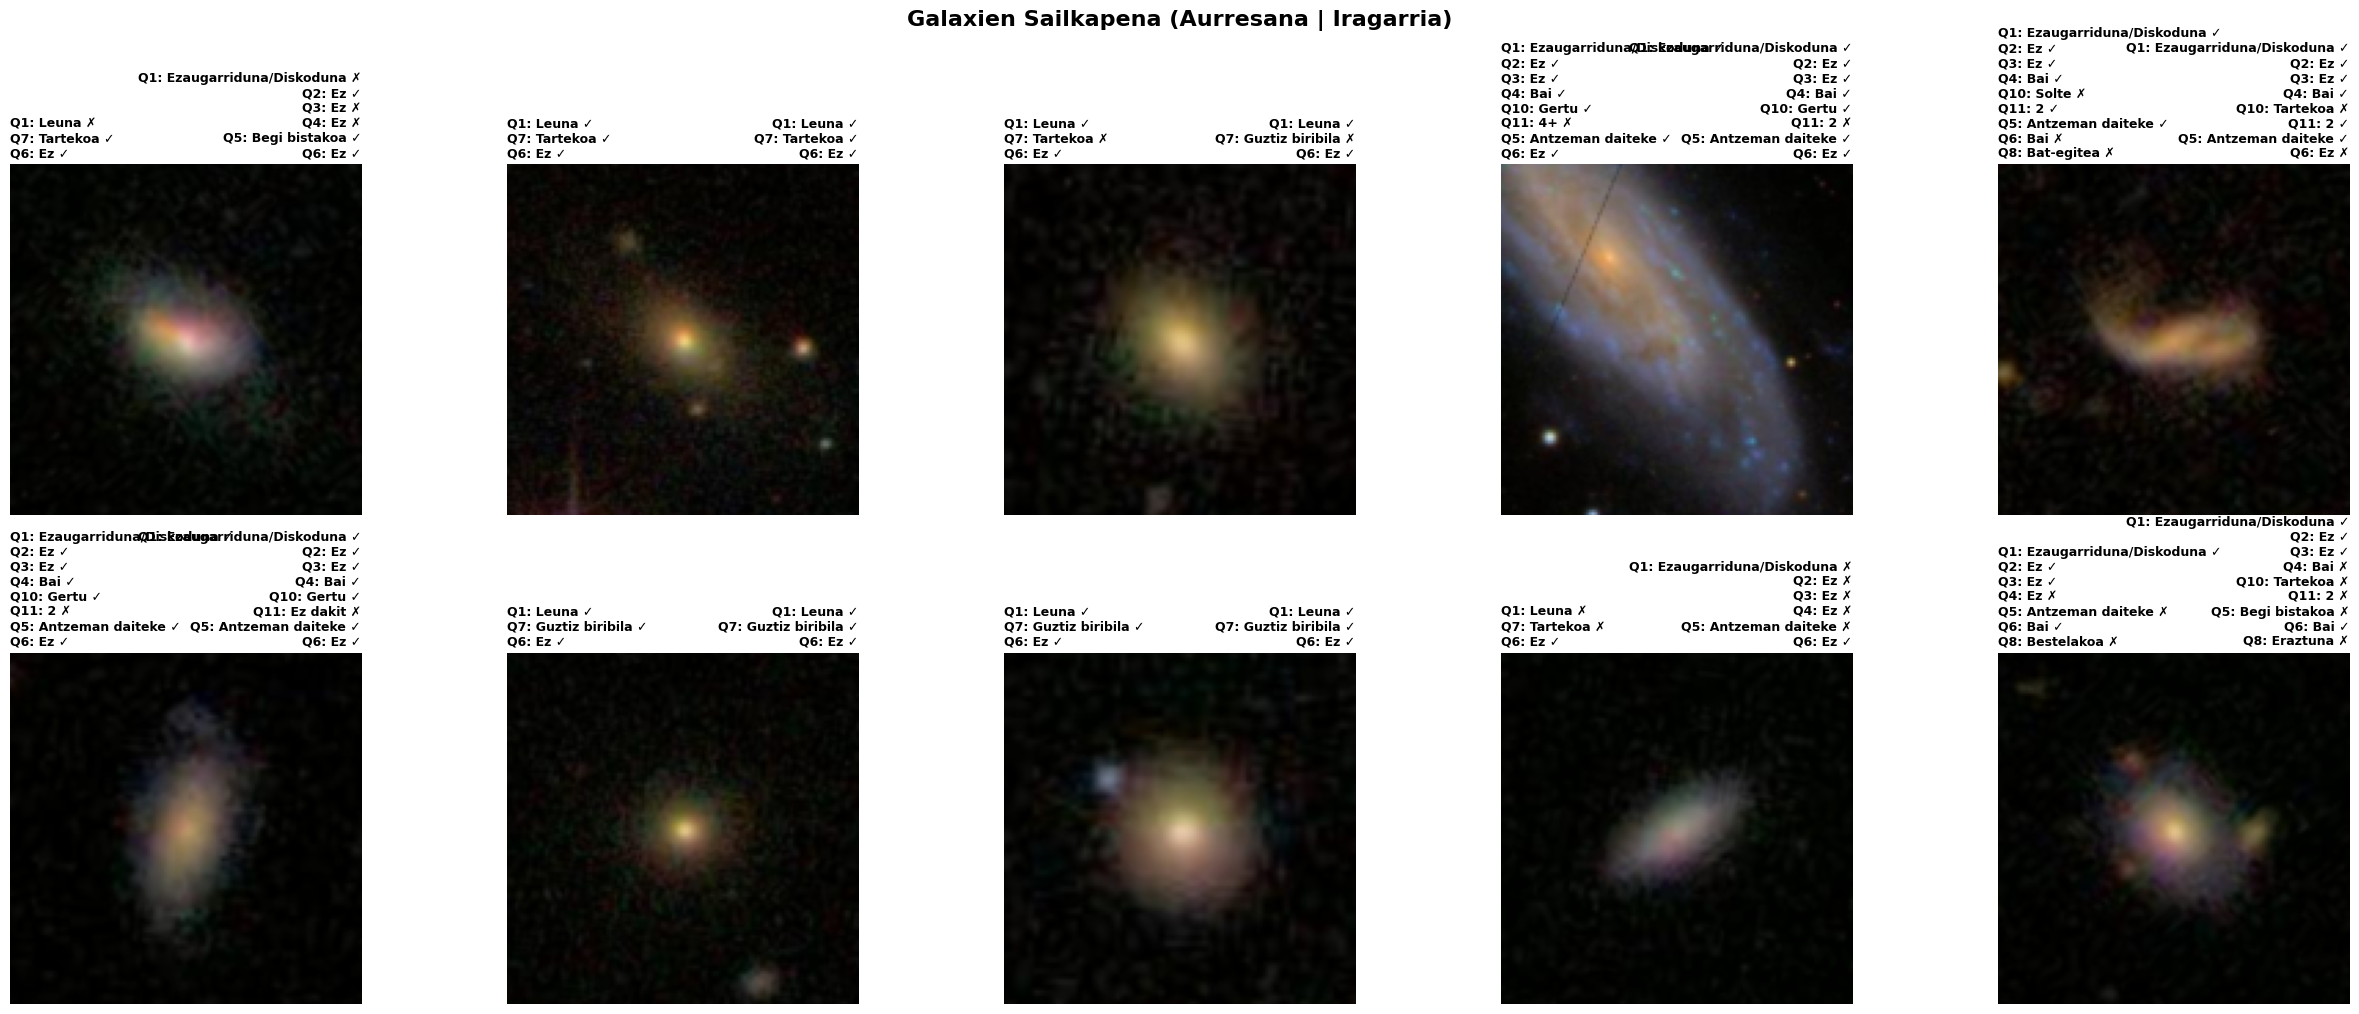

In [ ]:
# Proba exekutatzeko lagin kopurua
num_samples = 10

# Ausazko 10 lagin eskuratu proba datu-azpimultzotik
test_samples_dataloader = DataLoader(test_set, batch_size=num_samples, shuffle=True, generator=torch_generator)

# Proba exekutatu hautatutako laginekin
testing_loop(test_samples_dataloader, num_samples, model, device)